# Mobil Cihaz Fiyat Aralığı Tahmini - Keşifsel Veri Analizi (EDA)
**Hazırlayan:** Gürkan Tural (Veri Analisti)  
**Ders:** Araştırma Teknikleri  
**Görev Kapsamı:**
- Veri setini (CSV) Python (Pandas) ile projeye yüklemek.
- Satır/sütun sayılarını ve veri tiplerini (`info()`, `describe()`) kontrol etmek.
- 4 fiyat segmentinin (`0, 1, 2, 3`) veri setindeki dağılımına bakmak.

In [12]:
import os

# train.csv dosyasının varlığını ve boyutunu kontrol ediyoruz
file_path = "train.csv"
if os.path.exists(file_path) and os.path.getsize(file_path) > 0:
    print(f"'{file_path}' dosyası başarıyla algılandı ve kullanıma hazır!")
else:
    print(f"HATA: '{file_path}' bulunamadı veya boş! Lütfen dosyayı sol menüden yükleyin.")

'train.csv' dosyası başarıyla algılandı ve kullanıma hazır!


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# 1. Veri Setinin Yüklenmesi
try:
    df = pd.read_csv("train.csv")
    print("Veri seti başarıyla yüklendi. İlk 5 satır:")
    display(df.head())
except Exception as e:
    print(f"Veri yüklenirken bir hata oluştu: {e}")

Veri seti başarıyla yüklendi. İlk 5 satır:


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


## 2. Satır/Sütun Sayıları, Veri Tipleri ve Özet İstatistikler

In [14]:
# df'in tanımlı olduğundan emin olalım
if 'df' in locals() or 'df' in globals():
    print(f"Toplam Satır Sayısı: {df.shape[0]}")
    print(f"Toplam Sütun Sayısı: {df.shape[1]}")

    print("\n--- Veri Tipleri ve Bellek Kullanımı (info) ---")
    df.info()

    print("\n--- Sütun Bazında Eksik Değer Sayısı ---")
    print(df.isnull().sum())

    print("\n--- Sayısal Değişkenlerin Özet İstatistikleri (describe) ---")
    display(df.describe().T)
else:
    print("Lütfen önce veri setini yükleyen hücreyi (RgH_nkY58FvJ) çalıştırın.")

Toplam Satır Sayısı: 2000
Toplam Sütun Sayısı: 21

--- Veri Tipleri ve Bellek Kullanımı (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 1

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


## 3. Fiyat Segmentlerinin (0, 1, 2, 3) Veri Setindeki Dağılımı

,Fiyat Segmenti,Cihaz Sayısı,Oran (%)
0,0 (Düşük),500,25.0
1,1 (Orta),500,25.0
2,2 (Yüksek),500,25.0
3,3 (Çok Yüksek),500,25.0


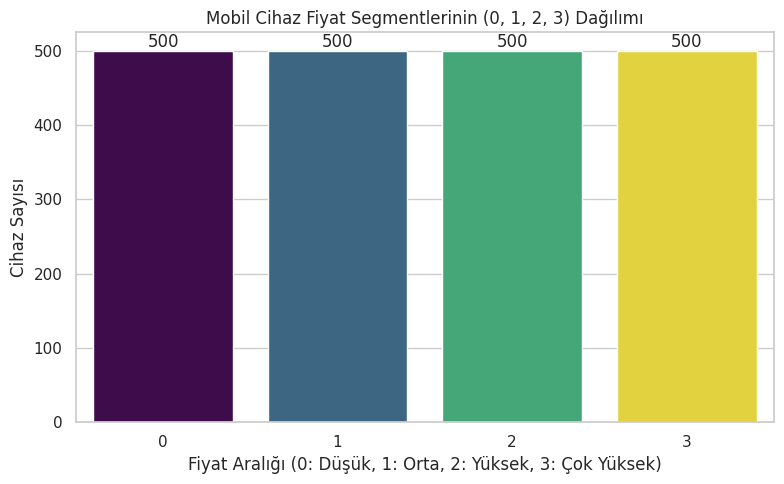

In [15]:
if 'df' in locals() or 'df' in globals():
    if "price_range" in df.columns:
        sinif_sayilari = df["price_range"].value_counts().sort_index()
        sinif_yuzdeleri = df["price_range"].value_counts(normalize=True).sort_index() * 100

        dagilim_tablosu = pd.DataFrame({
            "Fiyat Segmenti": ["0 (Düşük)", "1 (Orta)", "2 (Yüksek)", "3 (Çok Yüksek)"],
            "Cihaz Sayısı": sinif_sayilari.values,
            "Oran (%)": sinif_yuzdeleri.values
        })
        display(dagilim_tablosu)

        # Grafik çizimi
        plt.figure(figsize=(8, 5))
        ax = sns.countplot(x="price_range", data=df, hue="price_range", palette="viridis", legend=False)
        plt.title("Mobil Cihaz Fiyat Segmentlerinin (0, 1, 2, 3) Dağılımı")
        plt.xlabel("Fiyat Aralığı (0: Düşük, 1: Orta, 2: Yüksek, 3: Çok Yüksek)")
        plt.ylabel("Cihaz Sayısı")

        for container in ax.containers:
            ax.bar_label(container)

        plt.tight_layout()
        plt.show()
    else:
        print("Hata: Veri setinde 'price_range' sütunu bulunamadı!")
else:
    print("Lütfen önce veri setini yükleyen hücreyi (RgH_nkY58FvJ) çalıştırın.")

## 4. Donanım Özelliklerinin (RAM, Batarya, Ekran Çözünürlüğü) Fiyata Etkisi

Bu bölümde, mobil cihaz fiyatlarını en çok etkilediği düşünülen temel donanım özelliklerinin fiyat segmentlerine göre dağılımını inceleyeceğiz:
- **RAM (Bellek)**
- **Batarya Gücü (Battery Power)**
- **Ekran Çözünürlüğü (Piksel Yüksekliği x Genişliği)**

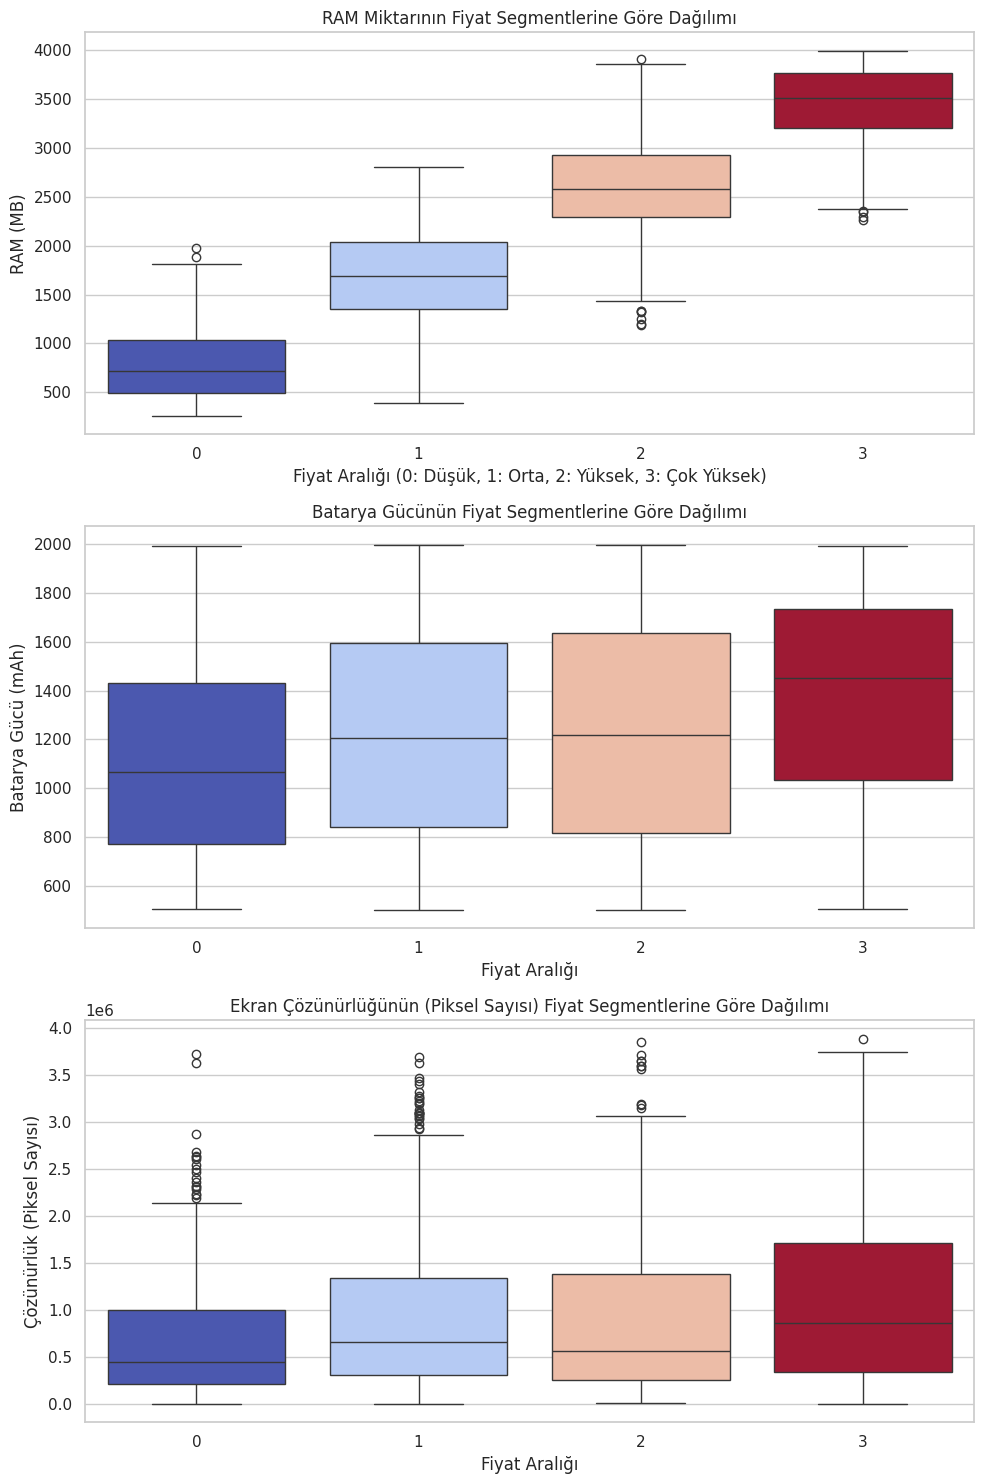

In [18]:
if 'df' in locals() or 'df' in globals():
    # Toplam ekran piksel sayısını hesaplayarak yeni bir özellik (ekran_cozunurluk) oluşturalım
    df['screen_resolution'] = df['px_height'] * df['px_width']

    # Grafik alanını hazırlayalım (3 satır, 1 sütun)
    fig, axes = plt.subplots(3, 1, figsize=(10, 15))

    # 1. RAM vs Fiyat Segmenti (Kutu Grafiği - Boxplot)
    sns.boxplot(ax=axes[0], x='price_range', y='ram', data=df, hue='price_range', palette='coolwarm', legend=False)
    axes[0].set_title('RAM Miktarının Fiyat Segmentlerine Göre Dağılımı')
    axes[0].set_xlabel('Fiyat Aralığı (0: Düşük, 1: Orta, 2: Yüksek, 3: Çok Yüksek)')
    axes[0].set_ylabel('RAM (MB)')

    # 2. Batarya Gücü vs Fiyat Segmenti (Kutu Grafiği - Boxplot)
    sns.boxplot(ax=axes[1], x='price_range', y='battery_power', data=df, hue='price_range', palette='coolwarm', legend=False)
    axes[1].set_title('Batarya Gücünün Fiyat Segmentlerine Göre Dağılımı')
    axes[1].set_xlabel('Fiyat Aralığı')
    axes[1].set_ylabel('Batarya Gücü (mAh)')

    # 3. Ekran Çözünürlüğü vs Fiyat Segmenti (Kutu Grafiği - Boxplot)
    sns.boxplot(ax=axes[2], x='price_range', y='screen_resolution', data=df, hue='price_range', palette='coolwarm', legend=False)
    axes[2].set_title('Ekran Çözünürlüğünün (Piksel Sayısı) Fiyat Segmentlerine Göre Dağılımı')
    axes[2].set_xlabel('Fiyat Aralığı')
    axes[2].set_ylabel('Çözünürlük (Piksel Sayısı)')

    plt.tight_layout()
    plt.show()
else:
    print("Lütfen önce veri setini yükleyen hücreyi çalıştırın.")

## 5. Donanım Özellikleri Arasındaki İlişkiler (Korelasyon Matrisi - Heatmap)

Fiyatı belirleyen ana etkenleri ve donanım özellikleri arasındaki doğrusal ilişkileri gözlemlemek amacıyla korelasyon matrisini bir Isı Haritası (Heatmap) üzerinde görselleştiriyoruz.

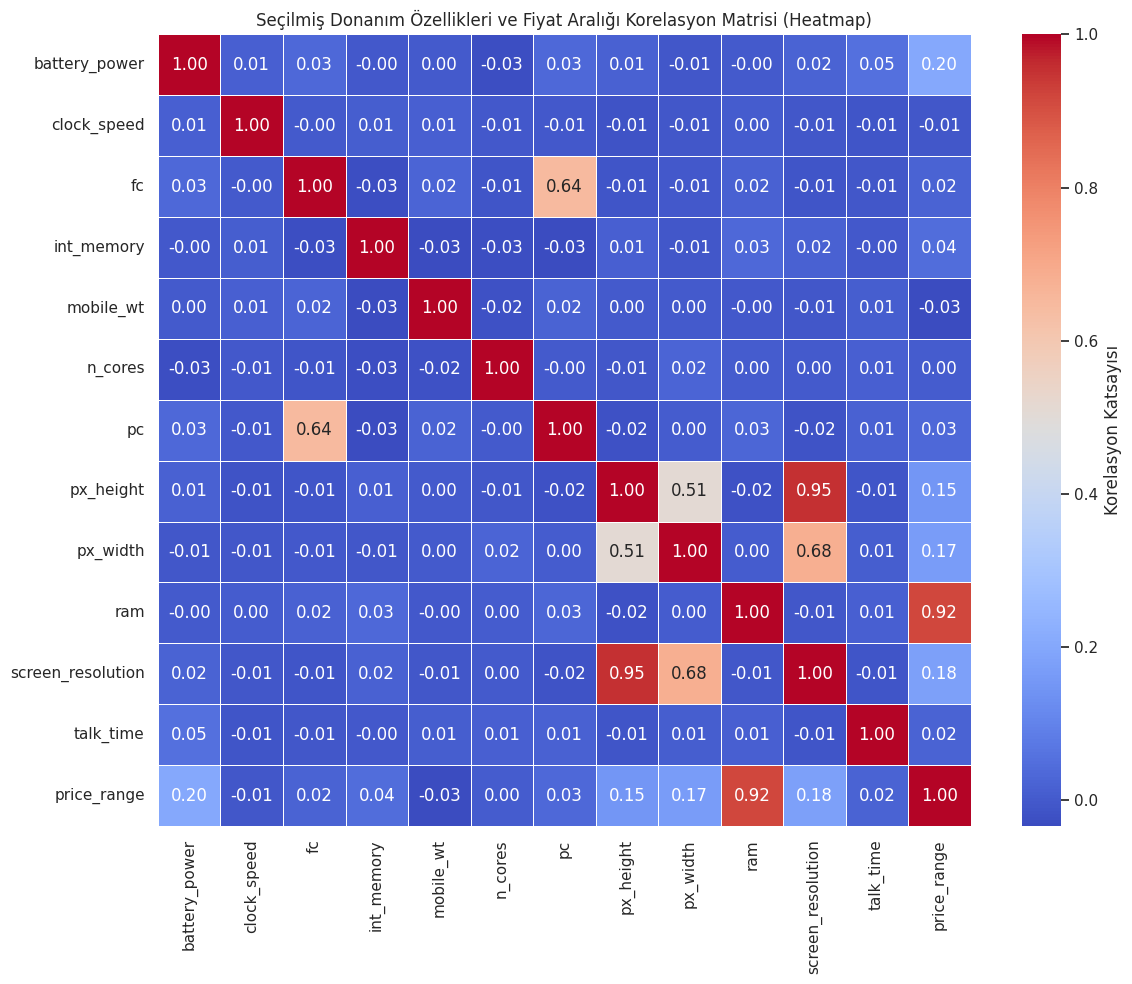

In [19]:
if 'df' in locals() or 'df' in globals():
    # Korelasyon matrisi için önemli ve belirgin donanım özelliklerini seçelim
    selected_features = [
        'battery_power', 'clock_speed', 'fc', 'int_memory',
        'mobile_wt', 'n_cores', 'pc', 'px_height',
        'px_width', 'ram', 'screen_resolution', 'talk_time', 'price_range'
    ]

    corr_matrix = df[selected_features].corr()

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        fmt='.2f',
        linewidths=0.5,
        cbar_kws={'label': 'Korelasyon Katsayısı'}
    )
    plt.title('Seçilmiş Donanım Özellikleri ve Fiyat Aralığı Korelasyon Matrisi (Heatmap)')
    plt.tight_layout()
    plt.show()
else:
    print("Lütfen önce veri setini yükleyen hücreyi çalıştırın.")